In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("train.csv")

In [5]:
df.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [9]:
df.shape

(1460, 81)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [12]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.isnull().sum().sort_values(ascending=False)

PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
                 ... 
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
SalePrice           0
Length: 81, dtype: int64

In [16]:
df.isnull().sum().sum()

np.int64(7829)

In [17]:
(df.isnull().sum() / len(df)) * 100

Id                0.000000
MSSubClass        0.000000
MSZoning          0.000000
LotFrontage      17.739726
LotArea           0.000000
                   ...    
MoSold            0.000000
YrSold            0.000000
SaleType          0.000000
SaleCondition     0.000000
SalePrice         0.000000
Length: 81, dtype: float64

In [18]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent[missing_percent > 0]

LotFrontage     17.739726
Alley           93.767123
MasVnrType      59.726027
MasVnrArea       0.547945
BsmtQual         2.534247
BsmtCond         2.534247
BsmtExposure     2.602740
BsmtFinType1     2.534247
BsmtFinType2     2.602740
Electrical       0.068493
FireplaceQu     47.260274
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
PoolQC          99.520548
Fence           80.753425
MiscFeature     96.301370
dtype: float64

SalePrice ka mean, median aur standard deviation check karo.

In [ ]:
df["SalePrice"].mean()

np.float64(180921.19589041095)

In [21]:
df["SalePrice"].median()

np.float64(163000.0)

In [22]:
df["SalePrice"].std()

np.float64(79442.50288288662)

In [23]:
df["SalePrice"].max()

np.int64(755000)

In [24]:
df["SalePrice"].min()

np.int64(34900)

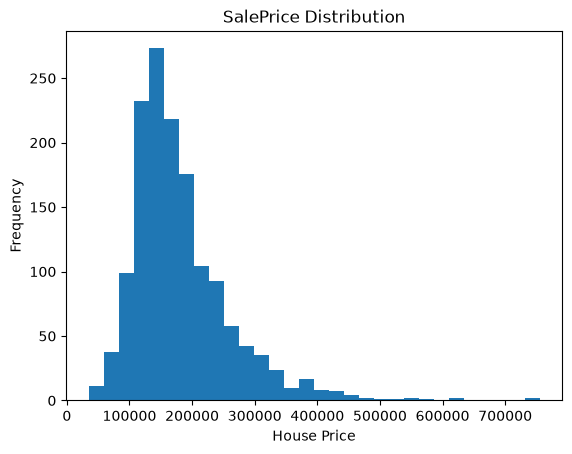

In [31]:
plt.hist(df["SalePrice"],bins=30)
plt.title("SalePrice Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()

SalePrice vs OverallQual ka boxplot

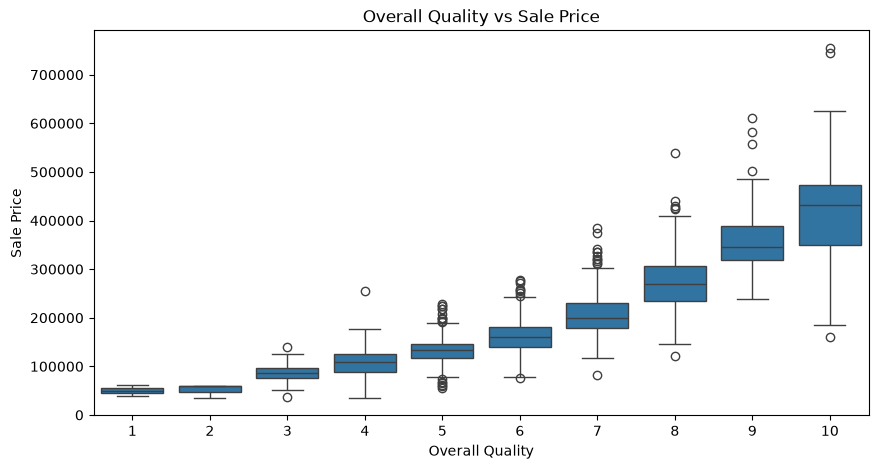

In [34]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["OverallQual"], y=df["SalePrice"])

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

Correlation Analysis

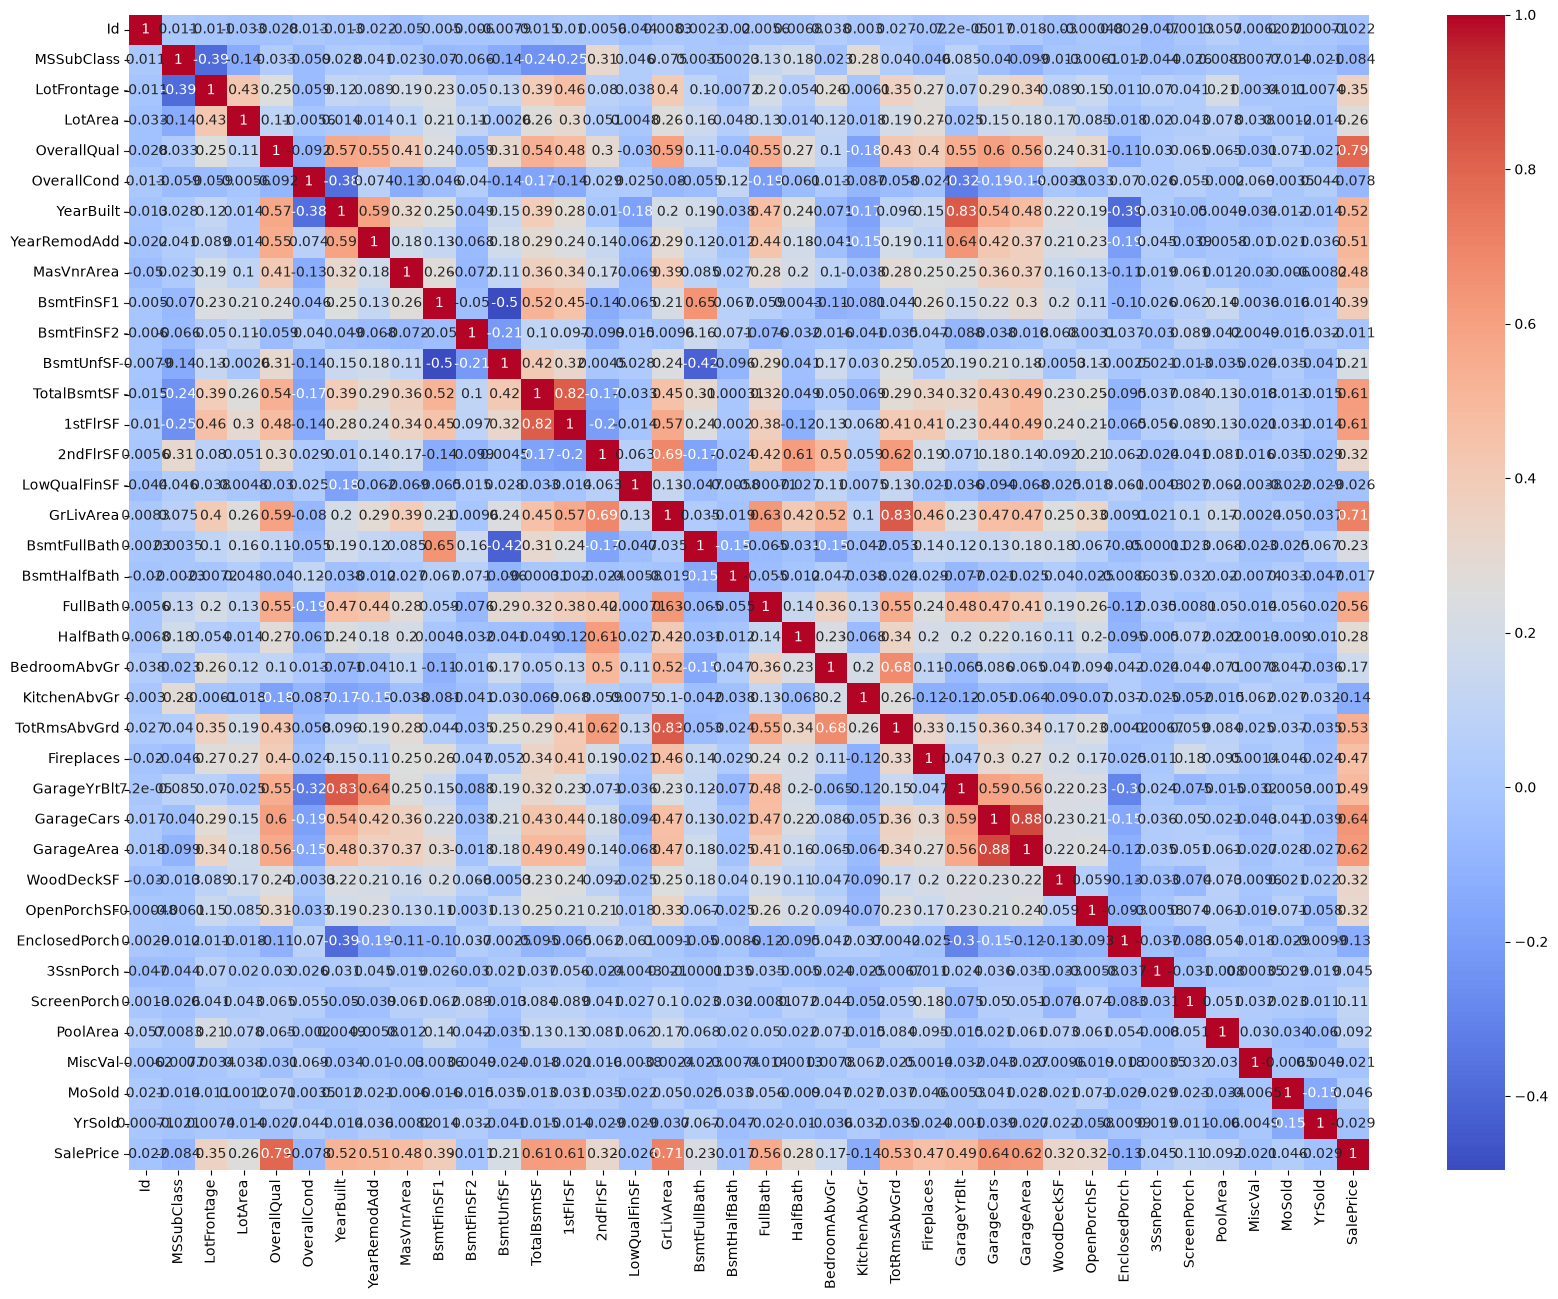

In [40]:
plt.figure(figsize=(20, 15))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()

TOP 10 FEATURES KA SALPRICE SE COOREALTION

In [42]:
corr = df.corr(numeric_only=True)

top_10 = corr["SalePrice"].drop("SalePrice").sort_values(
    ascending=False
).head(10)

print(top_10)

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


Ab ek scatter plot banao:

GrLivArea vs SalePrice

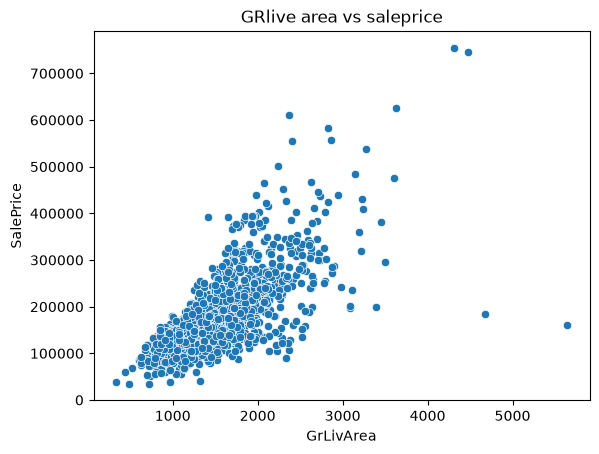

In [45]:
sns.scatterplot(x="GrLivArea",y="SalePrice",data=df)
plt.title("GRlive area vs saleprice")
plt.show()

Ab ye 3 tasks complete karo:
1. GarageCars vs SalePrice ka boxplot.
2. YearBuilt vs SalePrice ka scatter plot.
3. TotalBsmtSF vs SalePrice ka scatter plot.

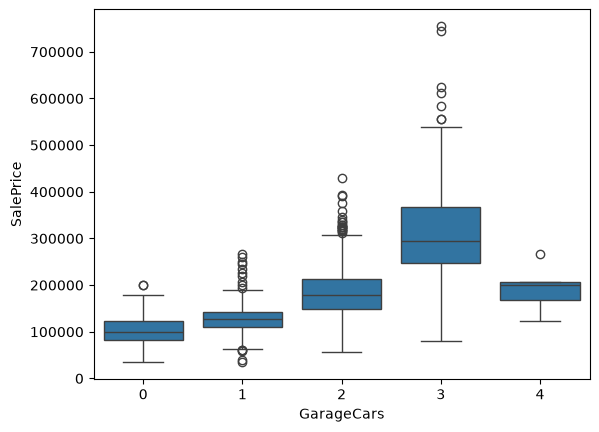

In [46]:
sns.boxplot(x=df["GarageCars"], y=df["SalePrice"])
plt.show()

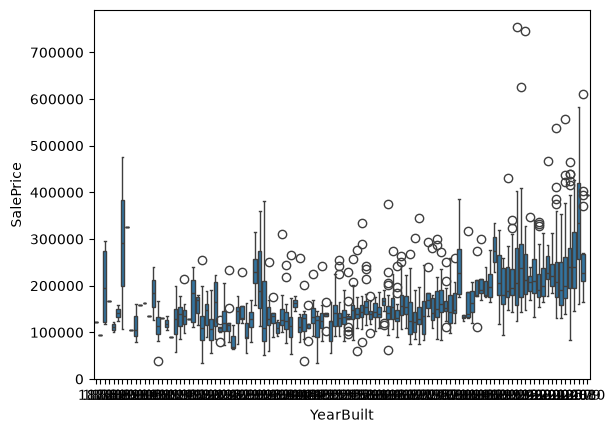

In [47]:
sns.boxplot(x=df["YearBuilt"], y=df["SalePrice"])
plt.show()

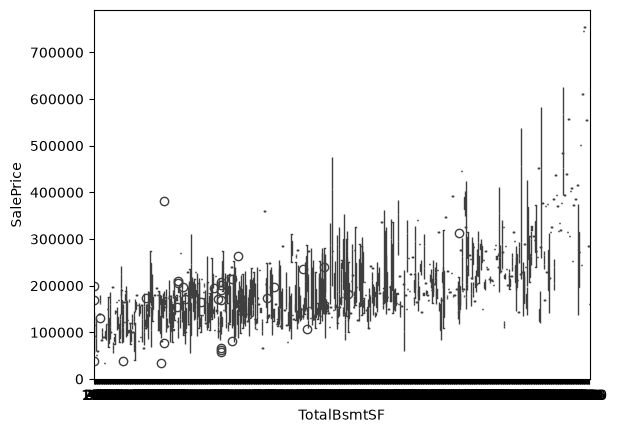

In [48]:
sns.boxplot(x=df["TotalBsmtSF"], y=df["SalePrice"])
plt.show()

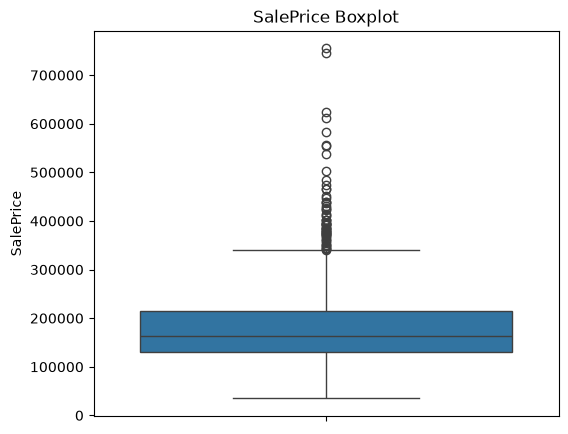

Lower fence: 3,938 | Upper fence: 340,038
Outliers: 61 (4.2%)
count        61.000000
mean     425954.180328
std       89557.255611
min      341000.000000
25%      372500.000000
50%      394617.000000
75%      440000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Skewness: 1.8828757597682129
Log-transformed skewness: 0.12134661989685333
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799
Name: SalePrice, dtype: float64

Important features (|r| >= 0.5):
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBu

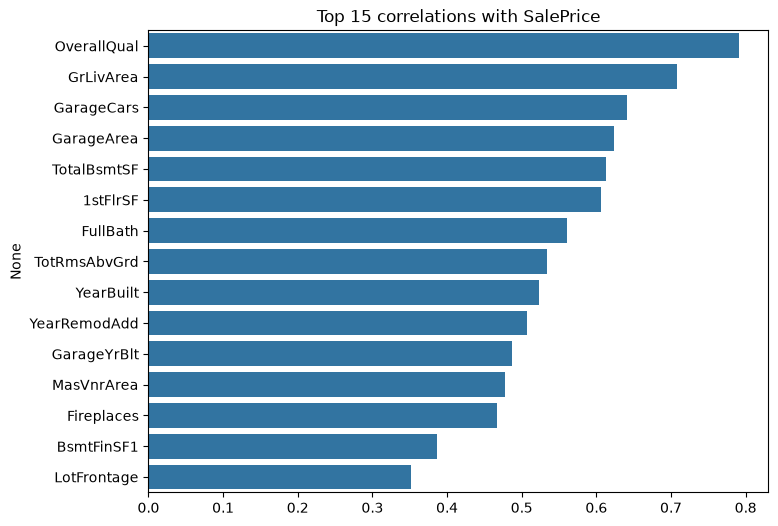

In [51]:


# 1. Boxplot + outliers (IQR method)
plt.figure(figsize=(6, 5))
sns.boxplot(y=df["SalePrice"])
plt.title("SalePrice Boxplot")
plt.show()

Q1, Q3 = df["SalePrice"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df["SalePrice"] < lower) | (df["SalePrice"] > upper)]

print(f"Lower fence: {lower:,.0f} | Upper fence: {upper:,.0f}")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(df):.1%})")
print(outliers["SalePrice"].describe())

# 2. Skewness
print("Skewness:", df["SalePrice"].skew())
print("Log-transformed skewness:", np.log1p(df["SalePrice"]).skew())

# 3. Correlation with SalePrice
num = df.select_dtypes(include="number")
corr = num.corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
print(corr.head(15))

important = corr[corr.abs() >= 0.5]
print("\nImportant features (|r| >= 0.5):")
print(important)

plt.figure(figsize=(8, 6))
sns.barplot(x=corr.head(15).values, y=corr.head(15).index)
plt.title("Top 15 correlations with SalePrice")
plt.show()

In [52]:

missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_pct = (missing / len(df) * 100).round(2)

summary = pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})

group1 = summary[summary["missing_%"] > 50]
group2 = summary[(summary["missing_%"] >= 10) & (summary["missing_%"] <= 50)]
group3 = summary[summary["missing_%"] < 10]

print("Group 1 (>50% missing):\n", group1, "\n")
print("Group 2 (10%-50% missing):\n", group2, "\n")
print("Group 3 (<10% missing):\n", group3)

# Sirf column names ki list
print(list(group1.index), list(group2.index), list(group3.index), sep="\n")

Group 1 (>50% missing):
              missing_count  missing_%
PoolQC                1453      99.52
MiscFeature           1406      96.30
Alley                 1369      93.77
Fence                 1179      80.75
MasVnrType             872      59.73 

Group 2 (10%-50% missing):
              missing_count  missing_%
FireplaceQu            690      47.26
LotFrontage            259      17.74 

Group 3 (<10% missing):
               missing_count  missing_%
GarageQual               81       5.55
GarageFinish             81       5.55
GarageType               81       5.55
GarageYrBlt              81       5.55
GarageCond               81       5.55
BsmtFinType2             38       2.60
BsmtExposure             38       2.60
BsmtCond                 37       2.53
BsmtQual                 37       2.53
BsmtFinType1             37       2.53
MasVnrArea                8       0.55
Electrical                1       0.07
['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']
['Fireplace

In [53]:
group1

,missing_count,missing_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73


In [55]:
print(group1.columns)
print(group1.index)

Index(['missing_count', 'missing_%'], dtype='str')
Index(['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType'], dtype='str')


In [56]:
for col in group1.index:
    df[col] = df[col].fillna("None")

In [58]:
df[group1.index].isnull().sum()

PoolQC         0
MiscFeature    0
Alley          0
Fence          0
MasVnrType     0
dtype: int64

In [59]:
group2

,missing_count,missing_%
FireplaceQu,690,47.26
LotFrontage,259,17.74


In [60]:
df["FireplaceQu"] = df["FireplaceQu"].fillna("None")

In [61]:
df["FireplaceQu"].isnull().sum()

np.int64(0)

In [63]:
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

In [64]:
df["LotFrontage"].isnull().sum()

np.int64(0)

In [65]:
group3

,missing_count,missing_%
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageCond,81,5.55
BsmtFinType2,38,2.60
BsmtExposure,38,2.60
BsmtCond,37,2.53
BsmtQual,37,2.53
BsmtFinType1,37,2.53


In [68]:
cat_cols = [
    'GarageQual', 'GarageFinish', 'GarageType',
    'GarageCond', 'BsmtFinType2', 'BsmtExposure',
    'BsmtCond', 'BsmtQual', 'BsmtFinType1'
]
for col in cat_cols:
    df[col] = df[col].fillna("None")

In [69]:
df[cat_cols].isnull().sum()

GarageQual      0
GarageFinish    0
GarageType      0
GarageCond      0
BsmtFinType2    0
BsmtExposure    0
BsmtCond        0
BsmtQual        0
BsmtFinType1    0
dtype: int64

In [ ]:
num_col=["GarageYrBlt","MasVnrArea"]

In [72]:
df["GarageYrBlt"]=df["GarageYrBlt"].fillna(df["GarageYrBlt"].median())
df["MasVnrArea"]=df["MasVnrArea"].fillna(df["MasVnrArea"].median())

In [74]:
df["MasVnrArea"].isnull().sum() ,df["GarageYrBlt"].isnull().sum()

(np.int64(0), np.int64(0))

In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

Id column ko dataset se remove karo.

In [76]:
df.drop(columns="Id",inplace=True)

In [77]:
df.shape

(1460, 80)

In [78]:
str_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(len(str_cols))
print(str_cols)

43
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [80]:
for col in str_cols:
    print(col, ":", df[col].unique()[:10])

MSZoning : <StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str
Street : <StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str
Alley : <StringArray>
['None', 'Grvl', 'Pave']
Length: 3, dtype: str
LotShape : <StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str
LandContour : <StringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str
Utilities : <StringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str
LotConfig : <StringArray>
['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']
Length: 5, dtype: str
LandSlope : <StringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str
Neighborhood : <StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer']
Length: 10, dtype: str
Condition1 : <StringArray>
['Norm', 'Feedr', 'PosN', 'Artery', 'RRAe', 'RRNn', 'RRAn', 'PosA', 'RRNe']
Length: 9, dtype: str
Condition2 : <StringArray>
['Norm', 'Artery', 'RRNn', 'Feedr', 'PosN', 'PosA', 'RRAn', 'RRAe']
Length: 8, dty

In [81]:
for col in ["ExterQual", "HeatingQC", "BsmtQual"]:
    print(col, df[col].unique())

ExterQual <StringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str
HeatingQC <StringArray>
['Ex', 'Gd', 'TA', 'Fa', 'Po']
Length: 5, dtype: str
BsmtQual <StringArray>
['Gd', 'TA', 'Ex', 'None', 'Fa']
Length: 5, dtype: str


In [83]:
from sklearn.preprocessing import OrdinalEncoder
categories = [
    ["Fa", "TA", "Gd", "Ex"],
    ["Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Fa", "TA", "Gd", "Ex"]
]
encoder = OrdinalEncoder(categories=categories)

In [84]:
ord_cols = ["ExterQual", "HeatingQC", "BsmtQual"]

df[ord_cols] = encoder.fit_transform(df[ord_cols])

In [85]:
df[ord_cols].head()

,ExterQual,HeatingQC,BsmtQual
0,2.0,4.0,3.0
1,1.0,4.0,3.0
2,2.0,4.0,3.0
3,1.0,3.0,2.0
4,2.0,4.0,3.0


In [86]:
nom_cols = [
    "MSZoning", "Street", "Alley", "LandContour",
    "Utilities", "LotConfig", "Neighborhood",
    "Condition1", "Condition2", "BldgType",
    "HouseStyle", "RoofStyle", "RoofMatl",
    "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "CentralAir",
    "Electrical", "GarageType", "PavedDrive",
    "SaleType", "SaleCondition"
]

In [87]:
df = pd.get_dummies(df, columns=nom_cols, drop_first=True, dtype=int)

In [88]:
df.shape

(1460, 201)

In [89]:
df.dtypes.value_counts()

int64      179
str         16
float64      6
Name: count, dtype: int64

In [90]:
remaining_str = df.select_dtypes(include=["str", "object", "string"]).columns.tolist()

print(len(remaining_str))
print(remaining_str)

16
['LotShape', 'LandSlope', 'ExterCond', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']


In [91]:
df = pd.get_dummies(df, columns=["MiscFeature"], drop_first=True, dtype=int)

In [92]:
df.shape

(1460, 204)

In [93]:
ord_remaining = [
    "LotShape", "LandSlope", "ExterCond", "BsmtCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "KitchenQual", "Functional", "FireplaceQu",
    "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence"
]

for col in ord_remaining:
    print(col, ":", df[col].unique())

LotShape : <StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str
LandSlope : <StringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str
ExterCond : <StringArray>
['TA', 'Gd', 'Fa', 'Po', 'Ex']
Length: 5, dtype: str
BsmtCond : <StringArray>
['TA', 'Gd', 'None', 'Fa', 'Po']
Length: 5, dtype: str
BsmtExposure : <StringArray>
['No', 'Gd', 'Mn', 'Av', 'None']
Length: 5, dtype: str
BsmtFinType1 : <StringArray>
['GLQ', 'ALQ', 'Unf', 'Rec', 'BLQ', 'None', 'LwQ']
Length: 7, dtype: str
BsmtFinType2 : <StringArray>
['Unf', 'BLQ', 'None', 'ALQ', 'Rec', 'LwQ', 'GLQ']
Length: 7, dtype: str
KitchenQual : <StringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str
Functional : <StringArray>
['Typ', 'Min1', 'Maj1', 'Min2', 'Mod', 'Maj2', 'Sev']
Length: 7, dtype: str
FireplaceQu : <StringArray>
['None', 'TA', 'Gd', 'Fa', 'Ex', 'Po']
Length: 6, dtype: str
GarageFinish : <StringArray>
['RFn', 'Unf', 'Fin', 'None']
Length: 4, dtype: str
GarageQual : <StringArray>
['TA', 'Fa', 'Gd', 'None', 'Ex',

In [94]:
for col in ["Functional", "GarageFinish", "Fence", "FireplaceQu"]:
    print(col, df[col].unique())

Functional <StringArray>
['Typ', 'Min1', 'Maj1', 'Min2', 'Mod', 'Maj2', 'Sev']
Length: 7, dtype: str
GarageFinish <StringArray>
['RFn', 'Unf', 'Fin', 'None']
Length: 4, dtype: str
Fence <StringArray>
['None', 'MnPrv', 'GdWo', 'GdPrv', 'MnWw']
Length: 5, dtype: str
FireplaceQu <StringArray>
['None', 'TA', 'Gd', 'Fa', 'Ex', 'Po']
Length: 6, dtype: str


In [98]:
from sklearn.preprocessing import OrdinalEncoder

categories = [
    ["IR3", "IR2", "IR1", "Reg"],
    ["Sev", "Mod", "Gtl"],
    ["Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd"],
    ["None", "No", "Mn", "Av", "Gd"],
    ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["Fa", "TA", "Gd", "Ex"],
    ["Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Unf", "RFn", "Fin"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Fa", "TA", "Gd", "Ex"],
    ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"]
]

encoder = OrdinalEncoder(categories=categories)
df[ord_remaining] = encoder.fit_transform(df[ord_remaining])

In [99]:
df.dtypes.value_counts()

int64      183
float64     21
Name: count, dtype: int64

In [101]:
df.isnull().sum().sum()

np.int64(0)

In [102]:
df.shape

(1460, 204)

In [104]:
X=df.drop(columns=["SalePrice"])
y=df["SalePrice"]

In [105]:
print(X.shape)
print(y.shape)

(1460, 203)
(1460,)


In [106]:
from sklearn.model_selection import train_test_split

In [107]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [108]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(1168, 203)
(292, 203)
(1168,)
(292,)


In [111]:
from sklearn.linear_model import LinearRegression

In [112]:
lr=LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](203,)","[ -61.67, -140.61, 0.3 ,..., 50891.61, 34686.18,-11550.25]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](203,)","['MSSubClass','LotFrontage','LotArea',...,'MiscFeature_Othr', 'MiscFeature_Shed','MiscFeature_TenC']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.541e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,203
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(194)


In [114]:
lr.score(X_train,y_train) *100 ,lr.score(X_test,y_test) * 100

(89.87375076375115, 86.79263126226823)

In [115]:
y_pred=lr.predict(X_test)

In [116]:
print(y_pred[:10])

[156369.6125116  333781.05444875 104871.0779108  196522.66694164
 300975.30207895  75788.24126637 248832.19406054 144662.06909393
  71413.53106013 146135.98002018]


actuall prices

In [117]:
print(y_test[:10].values)

[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]


In [125]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score,root_mean_squared_error

In [119]:
mae=mean_absolute_error(y_test,y_pred)
mae

20663.241032116395

In [120]:
mse=mean_squared_error(y_test,y_pred)
mse

1013048265.5700797

In [ ]:
r=r2_score(y_test,y_pred)
r


0.8679263126226823

In [126]:
rmse=root_mean_squared_error(y_test,y_pred)
rmse

31828.419149717123

In [127]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})



In [128]:
comparison.head(10)

,Actual,Predicted
0,154500,156369.612512
1,325000,333781.054449
2,115000,104871.077911
3,159000,196522.666942
4,315500,300975.302079
5,75500,75788.241266
6,311500,248832.194061
7,146000,144662.069094
8,84500,71413.531060
9,135500,146135.980020


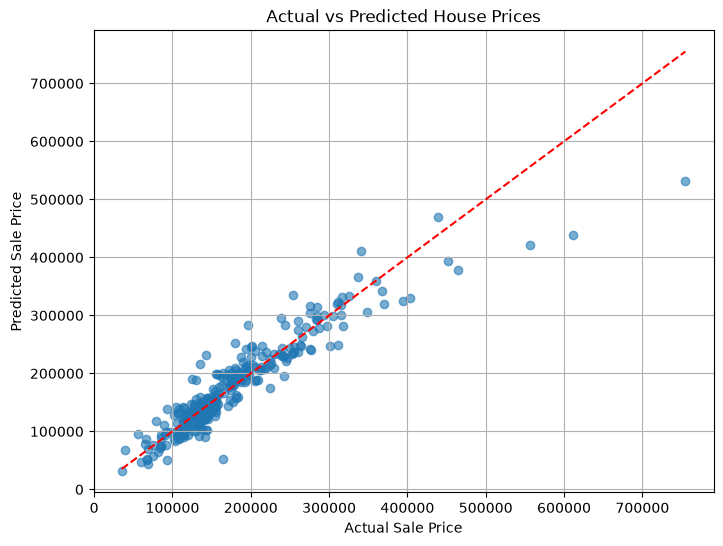

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()

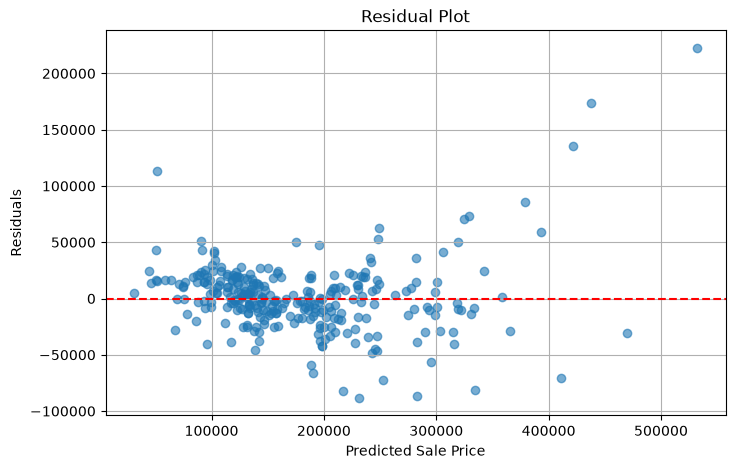

In [131]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

In [132]:
import numpy as np

y_log = np.log1p(y)

In [133]:
x_train, x_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

In [134]:
lr_log = LinearRegression()

lr_log.fit(X_train, y_train_log)

y_pred_log = lr_log.predict(X_test)

In [135]:
y_pred_original = np.expm1(y_pred_log)

In [138]:
mae_log = mean_absolute_error(y_test, y_pred_original)

mse_log = mean_squared_error(y_test, y_pred_original)

rmse_log = np.sqrt(mse_log)

r2_log = r2_score(y_test, y_pred_original)

print("MAE:", mae_log)
print("RMSE:", rmse_log)
print("R2 Score:", r2_log)

MAE: 15820.696840470386
RMSE: 23690.285878057835
R2 Score: 0.9268310590939103


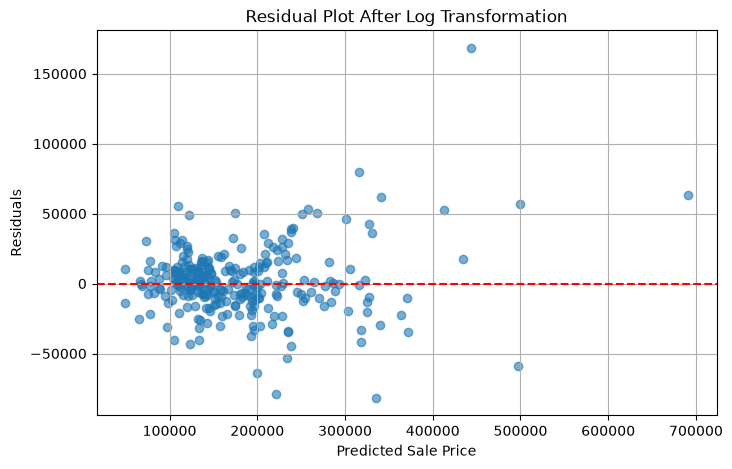

In [139]:
residuals_log = y_test - y_pred_original

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_original, residuals_log, alpha=0.6)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")
plt.title("Residual Plot After Log Transformation")
plt.grid(True)
plt.show()

In [140]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Log Linear Regression"],
    "MAE": [20663.24, mae_log],
    "RMSE": [31828.42, rmse_log],
    "R2 Score": [0.8679, r2_log]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20663.24000,31828.420000,0.867900
1,Log Linear Regression,15820.69684,23690.285878,0.926831


In [141]:
import joblib

joblib.dump(lr_log, "house_price_model.pkl")

['house_price_model.pkl']